# Q6 — Can Product Listing Prices Be Predicted From Technical Specifications Alone?
**CSC17104 Final Project — DDR5 and NVMe Prices in 12 U.S. ZIP Markets (2026)**  
**Question Owner:** Đức Khải (Class 24C10)  
**Milestone Status:** Day 30 — Target EDA, Leakage-Free Group Splitting & Baseline ML Setup

---

## 1. Research Question & Motivation
- **Research Question:** Can we accurately predict the listed retail price (`price_amount` in USD) of unseen DDR5 memory kits and NVMe SSDs using only hardware specifications parsed from their product titles (`category`, `capacity_gb`, `brand`, `form_factor`, `speed_mhz`, `cas_latency`, `kit_modules`, `pcie_gen`, `has_rgb`) and market location (`geography_id`)?
- **Practical Benefits:**
  1. Provides consumers and procurement teams with a fair-price benchmark ("fair value estimator") to detect overpriced listings or genuine bargains.
  2. Quantifies how much of hardware price variation is explained purely by baseline storage capacity (`capacity_gb`) versus secondary technical specifications (`brand`, `speed_mhz`, `pcie_gen`).
- **Methodological Guardrails (Strict Anti-Leakage Design):**
  1. **Zero Target Leakage:** `normalized_price_amount` and `price_per_unit_recomputed` are direct algebraic functions of `price_amount` and are **strictly excluded** from all feature matrices.
  2. **Group-Aware Splitting (`product_name`):** Because the dataset tracks 1,176 unique product titles across 12 ZIP codes and 29 days, standard random row splitting would place the exact same product title in both train and test sets (causing severe panel memorization). We enforce `GroupShuffleSplit` (80% train / 20% test) and 5-Fold `GroupKFold` grouped strictly by `product_name` to simulate predicting prices for **completely unseen products**.
  3. **Test Set Quarantine:** In accordance with the project plan, the 20% held-out test set is locked away during Day 30 and Stage 2, and will only be evaluated **once** in Stage 3 after final model selection.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False
})
sns.set_theme(style="whitegrid")

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.io import load_raw
from src.cleaning import RowLog, add_flags
from src.parse_titles import add_parsed_features

log = RowLog()
df_raw = load_raw(validate=True)
df = log.note(add_flags(df_raw), "add cleaning flags", reason="attach category, is_unresolved, is_system_noise")
df = log.note(add_parsed_features(df), "add parsed title features", reason="extract leakage-free hardware specs from product_name")

[OK] All 12 checks match the Kaggle data card.
[add cleaning flags] 127,843 -> 127,843 rows (removed 0)
[add parsed title features] 127,843 -> 127,843 rows (removed 0)
Master dataset loaded: 127,843 rows | 1,176 unique product titles.


## 2. Preprocessing & Target Variable EDA ($\log(\text{price\_amount})$)
To build a clean component-level regression dataset, we log every row removal explicitly via `RowLog`:
1. Exclude 17 complete computer system rows (`is_system_noise == True`) and 11 diskless NAS appliance rows (`is_nas_appliance == True`).
2. Exclude 4,340 NVMe rows with unresolved capacity (`is_unresolved == True`), as storage capacity is a primary physical determinant of hardware pricing.

In [2]:
# Explicit filtering logged with RowLog
q6_df = log.step(df, "drop complete systems (17 PC/Mini-PC rows)", lambda d: d[~d["is_system_noise"]], reason="exclude non-RAM computers")
q6_df = log.step(q6_df, "drop NAS appliances (11 NAS rows)", lambda d: d[~d["is_nas_appliance"]], reason="exclude diskless NAS boxes")
q6_df = log.step(q6_df, "drop unresolved capacity (4,340 NVMe rows)", lambda d: d[~d["is_unresolved"]].copy(), reason="require resolved capacity for component pricing")

# Unified capacity in GB (1 TB = 1,000 GB) and log-transformed target
q6_df["capacity_gb"] = np.where(
    q6_df["quantity_unit"].astype(str) == "terabytes",
    q6_df["quantity_value"] * 1000.0,
    q6_df["quantity_value"]
)
q6_df["log_price"] = np.log(q6_df["price_amount"])

print("\n=== Q6 ROW COUNT LOG ===")
display(log.table())

print("\n=== TARGET VARIABLE SUMMARY (RAW USD VS. LOG-PRICE) ===")
target_summary = q6_df.groupby("category", observed=True).agg(
    n_rows=("price_amount", "count"),
    n_products=("product_name", "nunique"),
    mean_usd=("price_amount", "mean"),
    std_usd=("price_amount", "std"),
    median_usd=("price_amount", "median"),
    min_usd=("price_amount", "min"),
    max_usd=("price_amount", "max"),
    skew_raw_usd=("price_amount", lambda s: s.skew()),
    skew_log_price=("log_price", lambda s: s.skew()),
).round(2)
display(target_summary)

[drop complete systems (17 PC/Mini-PC rows)] 127,843 -> 127,826 rows (removed 17)
[drop NAS appliances (11 NAS rows)] 127,826 -> 127,815 rows (removed 11)
[drop unresolved capacity (4,340 NVMe rows)] 127,815 -> 123,475 rows (removed 4,340)

=== Q6 ROW COUNT LOG ===


,step,rows_before,rows_after,rows_removed,reason
0,add cleaning flags,127843,127843,0,"attach category, is_unresolved, is_system_noise"
1,add parsed title features,127843,127843,0,extract leakage-free hardware specs from product_name
2,drop complete systems (17 PC/Mini-PC rows),127843,127826,17,exclude non-RAM computers
3,drop NAS appliances (11 NAS rows),127826,127815,11,exclude diskless NAS boxes
4,"drop unresolved capacity (4,340 NVMe rows)",127815,123475,4340,require resolved capacity for component pricing



=== TARGET VARIABLE SUMMARY (RAW USD VS. LOG-PRICE) ===


,n_rows,n_products,mean_usd,std_usd,median_usd,min_usd,max_usd,skew_raw_usd,skew_log_price
category,,,,,,,,,
DDR5,18622,221,790.75,993.26,479.99,109.99,8719.99,3.66,0.91
NVMe,104853,907,220.63,168.53,169.99,27.35,999.99,1.63,0.01


## 3. Feature Cardinality, Missingness & Leakage Audit
Before constructing the baseline models, we inspect the candidate features extracted from `product_name` to verify their cardinality and structural missingness across DDR5 and NVMe categories.

In [3]:
candidate_features = [
    "category", "capacity_gb", "brand", "form_factor",
    "speed_mhz", "cas_latency", "kit_modules", "pcie_gen",
    "has_rgb", "geography_id"
]

# Verify strict anti-leakage guard
FORBIDDEN_LEAKAGE_COLS = {"price_amount", "normalized_price_amount", "price_per_unit_recomputed", "log_price"}
assert FORBIDDEN_LEAKAGE_COLS.isdisjoint(set(candidate_features)), "FATAL: Target leakage detected in feature list!"

feat_audit = []
for col in candidate_features:
    for cat in ["DDR5", "NVMe"]:
        sub = q6_df[q6_df["category"] == cat]
        n_miss = int(sub[col].isna().sum())
        feat_audit.append({
            "feature": col,
            "category": cat,
            "n_unique": int(sub[col].nunique(dropna=True)),
            "pct_missing": round(100.0 * n_miss / len(sub), 2)
        })

feat_audit_df = pd.DataFrame(feat_audit).pivot(index="feature", columns="category", values=["n_unique", "pct_missing"])
print("=== CANDIDATE FEATURE CARDINALITY & MISSINGNESS (%) ===")
display(feat_audit_df)

=== CANDIDATE FEATURE CARDINALITY & MISSINGNESS (%) ===


n_unique        pct_missing        
category         DDR5   NVMe        DDR5    NVMe
feature                                         
brand            23.0  115.0        0.00    0.00
capacity_gb       8.0   16.0        0.00    0.00
cas_latency      12.0    0.0        0.52  100.00
category          1.0    1.0        0.00    0.00
form_factor       2.0    5.0        0.00    0.00
geography_id     12.0   12.0        0.00    0.00
has_rgb           2.0    2.0        0.00    0.00
kit_modules       3.0    1.0        0.00    0.00
pcie_gen          0.0    3.0      100.00   10.61
speed_mhz         7.0    0.0        0.00  100.00

## 4. Group-Aware Train/Test Split & Baseline Models (Day 30 Scope)
We partition the 123,475 observations into an **80% Train Set** (902 products; 99,992 rows) and a **20% Quarantine Test Set** (226 products; 23,483 rows) grouped by `product_name`.

On the **Train Set**, we evaluate three progressive **Baseline Models** using **5-Fold `GroupKFold`** cross-validation:
1. **Baseline 0 (`B0: Global Mean`):** Predicts the overall mean $\log(\text{price})$ across all training rows (`DummyRegressor` equivalent).
2. **Baseline 1 (`B1: Category Mean`):** Predicts the mean $\log(\text{price})$ separately for `DDR5` and `NVMe`.
3. **Baseline 2 (`B2: Category × Capacity Tier Lookup`):** Predicts the mean $\log(\text{price})$ conditioned on `(category, capacity_gb)` (with fallback to category mean if an unseen capacity tier appears). This establishes the benchmark for how much variance is explained by storage size alone.

In [4]:
# 1. Lock away 20% Test Set grouped by product_name
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(gss.split(q6_df, q6_df["log_price"], groups=q6_df["product_name"]))

train_df = q6_df.iloc[train_idx].copy()
test_df = q6_df.iloc[test_idx].copy()  # Quarantined until Stage 3!

overlap = set(train_df["product_name"]).intersection(set(test_df["product_name"]))
print(f"Train Set: {len(train_df):,} rows | {train_df['product_name'].nunique():,} unique products")
print(f"Test Set:  {len(test_df):,} rows | {test_df['product_name'].nunique():,} unique products (QUARANTINED)")
print(f"Product title overlap between Train and Test: {len(overlap)} (Strict zero-leakage verified)\n")

# 2. Evaluate Baselines via 5-Fold GroupKFold on Train Set
gkf = GroupKFold(n_splits=5)
cv_records = []

for fold, (tr_i, val_i) in enumerate(gkf.split(train_df, train_df["log_price"], groups=train_df["product_name"]), 1):
    tr = train_df.iloc[tr_i]
    val = train_df.iloc[val_i]
    
    y_true_log = val["log_price"].values
    y_true_usd = val["price_amount"].values
    
    # B0: Global Mean
    b0_pred_log = np.full(len(val), tr["log_price"].mean())
    
    # B1: Category Mean
    cat_means = tr.groupby("category", observed=True)["log_price"].mean().to_dict()
    b1_pred_log = val["category"].map(cat_means).astype(float).values
    
    # B2: Category x Capacity_GB Lookup Mean
    cat_cap_means = tr.groupby(["category", "capacity_gb"], observed=True)["log_price"].mean()
    b2_pred_log = val.set_index(["category", "capacity_gb"]).index.map(cat_cap_means).values
    b2_pred_log = np.where(np.isnan(b2_pred_log), b1_pred_log, b2_pred_log)
    
    for name, pred_log in [
        ("B0: Global Mean (Dummy)", b0_pred_log),
        ("B1: Category Mean (DDR5 vs NVMe)", b1_pred_log),
        ("B2: Category × Capacity Tier Lookup", b2_pred_log),
    ]:
        pred_usd = np.exp(pred_log)
        cv_records.append({
            "Model": name,
            "Fold": fold,
            "MAE_log": mean_absolute_error(y_true_log, pred_log),
            "RMSE_log (RMSLE)": root_mean_squared_error(y_true_log, pred_log),
            "R2_log": r2_score(y_true_log, pred_log),
            "MAE_USD ($)": mean_absolute_error(y_true_usd, pred_usd),
            "MAPE (%)": np.mean(np.abs(y_true_usd - pred_usd) / y_true_usd) * 100.0
        })

cv_df = pd.DataFrame(cv_records)
summary_cv = cv_df.groupby("Model", sort=False).agg(
    MAE_log_mean=("MAE_log", "mean"),
    MAE_log_std=("MAE_log", "std"),
    RMSLE_mean=("RMSE_log (RMSLE)", "mean"),
    RMSLE_std=("RMSE_log (RMSLE)", "std"),
    R2_log_mean=("R2_log", "mean"),
    MAE_USD_mean=("MAE_USD ($)", "mean"),
    MAPE_pct_mean=("MAPE (%)", "mean"),
).round(4)

print("=== 5-FOLD GROUPKFOLD BASELINE RESULTS (TRAIN SET) ===")
display(summary_cv)

Train Set: 99,992 rows | 902 unique products
Test Set:  23,483 rows | 226 unique products (QUARANTINED)
Product title overlap between Train and Test: 0 (Strict zero-leakage verified)

=== 5-FOLD GROUPKFOLD BASELINE RESULTS (TRAIN SET) ===


,MAE_log_mean,MAE_log_std,RMSLE_mean,RMSLE_std,R2_log_mean,MAE_USD_mean,MAPE_pct_mean
Model,,,,,,,
B0: Global Mean (Dummy),0.6737,0.0222,0.8470,0.0288,-0.0216,188.5337,81.3782
B1: Category Mean (DDR5 vs NVMe),0.5887,0.0435,0.7417,0.0264,0.2130,165.7079,68.7484
B2: Category × Capacity Tier Lookup,0.1978,0.0347,0.2624,0.0473,0.8984,52.2464,19.8761


## 5. Baseline Diagnostic Visualizations
We generate two diagnostic charts for the Day 30 milestone:
- **Left Panel:** Kernel density distribution of $\log(\text{price\_amount})$ across DDR5 and NVMe, demonstrating variance stabilization compared to raw USD skewness.
- **Right Panel:** 5-Fold `GroupKFold` cross-validation error (`MAE_log` and `RMSLE`) across the three baseline tiers.

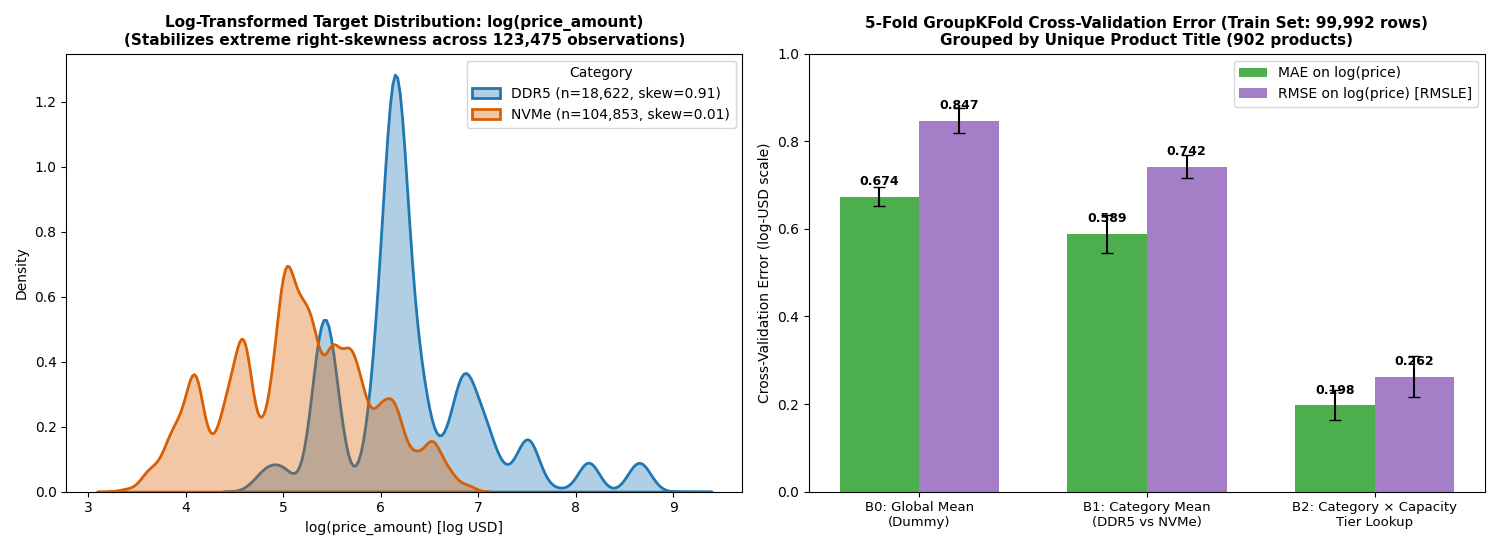

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for cat, color in [("DDR5", "#1f77b4"), ("NVMe", "#d95f02")]:
    sub = q6_df[q6_df["category"] == cat]
    sns.kdeplot(
        sub["log_price"], ax=axes[0],
        label=f"{cat} (n={len(sub):,}, skew={sub['log_price'].skew():.2f})",
        fill=True, alpha=0.35, color=color, linewidth=2
    )

axes[0].set_title("Log-Transformed Target Distribution: log(price_amount)\n(Stabilizes extreme right-skewness across 123,475 observations)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("log(price_amount) [log USD]", fontsize=10)
axes[0].set_ylabel("Density", fontsize=10)
axes[0].legend(title="Category")

models_short = ["B0: Global Mean\n(Dummy)", "B1: Category Mean\n(DDR5 vs NVMe)", "B2: Category × Capacity\nTier Lookup"]
mae_vals = summary_cv["MAE_log_mean"].values
rmse_vals = summary_cv["RMSLE_mean"].values
mae_errs = summary_cv["MAE_log_std"].values
rmse_errs = summary_cv["RMSLE_std"].values

x = np.arange(len(models_short))
width = 0.35

rects1 = axes[1].bar(x - width/2, mae_vals, width, yerr=mae_errs, capsize=4, label="MAE on log(price)", color="#2ca02c", alpha=0.85)
rects2 = axes[1].bar(x + width/2, rmse_vals, width, yerr=rmse_errs, capsize=4, label="RMSE on log(price) [RMSLE]", color="#9467bd", alpha=0.85)

axes[1].set_title("5-Fold GroupKFold Cross-Validation Error (Train Set: 99,992 rows)\nGrouped by Unique Product Title (902 products)", fontsize=11, fontweight="bold")
axes[1].set_xticks(x)
axes[1].set_xticklabels(models_short, fontsize=9.5)
axes[1].set_ylabel("Cross-Validation Error (log-USD scale)", fontsize=10)
axes[1].set_ylim(0, 1.0)
axes[1].legend()

for rect in rects1:
    h = rect.get_height()
    axes[1].annotate(f"{h:.3f}", xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 6), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
for rect in rects2:
    h = rect.get_height()
    axes[1].annotate(f"{h:.3f}", xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 6), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig("q6_day30_baseline_eda.png")
plt.show()

## 6. Key Findings from Day 30 Baseline & Next Steps for Stage 2
1. **Why Log Transformation is Essential:** Raw listing prices exhibit extreme positive skewness (`3.66` for DDR5 and `1.63` for NVMe). Applying $\log(\text{price\_amount})$ compresses skewness down to `0.91` for DDR5 and `0.01` for NVMe, preventing high-capacity enterprise kits (256 GB ECC RAM up to \$8,719.99) from dominating gradient updates.
2. **Baseline Hierarchy (`B0` → `B1` → `B2`):**
   - `B0 (Global Mean)` fails completely ($R^2_{\log} = -0.0216$, $\text{MAE}_{\log} = 0.6737$, $\text{MAPE} = 81.38\%$).
   - `B1 (Category Mean)` captures the price level separation between DDR5 and NVMe ($R^2_{\log} = 0.2130$, $\text{MAE}_{\log} = 0.5887$, $\text{MAPE} = 68.75\%$).
   - `B2 (Category × Capacity Lookup)` achieves a massive leap in predictive accuracy ($R^2_{\log} = 0.8984$, $\text{MAE}_{\log} = 0.1978$, $\text{RMSLE} = 0.2624$, $\text{MAE}_{\text{USD}} = \$52.25$, $\text{MAPE} = 19.88\%$). This proves that **category and storage capacity alone account for ~89.8% of log-price variance**, setting a strong, realistic bar that our machine learning models (`Ridge` and `HistGradientBoostingRegressor` / `RandomForestRegressor`) must beat in **Stage 2 (Nov 02–08)** by leveraging `brand`, `speed_mhz`, `cas_latency`, `form_factor`, `pcie_gen`, and `has_rgb`.